# Homework 2: Linear Regression

Predicción de la eficiencia de combustible (`fuel_efficiency_mpg`) a partir de
`engine_displacement`, `horsepower`, `vehicle_weight` y `model_year`.

Dataset: `car_fuel_efficiency_2026.csv` (release 2026 fijado en el repo del curso)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error

## Carga de datos

Descargado con `wget` desde el repo del curso:

```bash
wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
```

In [2]:
URL = (
    "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main"
    "/cohorts/2026/data/car_fuel_efficiency_2026.csv"
)

df = pd.read_csv(URL)
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


## Preparando el dataset

Usando solo las 5 columnas necesarias para el modelo.

In [3]:
cols = [
    "engine_displacement",
    "horsepower",
    "vehicle_weight",
    "model_year",
    "fuel_efficiency_mpg",
]

df = df[cols]
df.isna().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

## EDA: ¿tiene `fuel_efficiency_mpg` una cola larga?

Revisando distribución de la variable objetivo.

In [4]:
df["fuel_efficiency_mpg"].describe()

count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64

In [5]:
quantiles = df["fuel_efficiency_mpg"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]).to_frame("mpg")
print("skew:", round(df["fuel_efficiency_mpg"].skew(), 3))
quantiles

skew: 0.081


,mpg
0.50,30.000
0.75,31.900
0.90,33.800
0.95,34.905
0.99,36.900


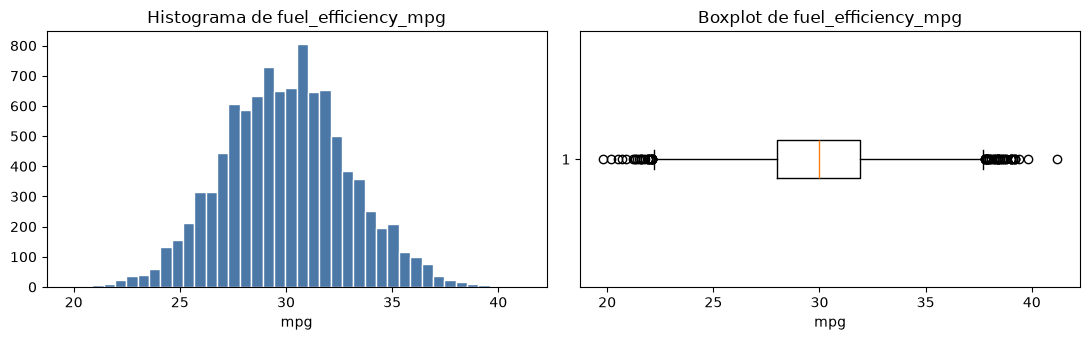

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

ax[0].hist(df["fuel_efficiency_mpg"], bins=40, color="#4C78A8", edgecolor="white")
ax[0].set_title("Histograma de fuel_efficiency_mpg")
ax[0].set_xlabel("mpg")

ax[1].boxplot(df["fuel_efficiency_mpg"], orientation="horizontal")
ax[1].set_title("Boxplot de fuel_efficiency_mpg")
ax[1].set_xlabel("mpg")

plt.tight_layout()

**Conclusión del EDA:** no hay cola larga. La distribución está centrada en ~30 mpg,
va de 19.8 a 41.2 mpg, con `skew = 0.08` (muy simétrica) y la cola derecha termina
en 41.2 frente al percentil 99 en 36.9. No hace falta aplicar `log1p` ni
`np.log1p` a la variable objetivo ni a las features.

## Question 1

Una columna tiene valores faltantes. ¿Cuál es?

In [7]:
df.isna().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

**Respuesta Q1: `horsepower`** (877 valores `NaN` de 10000 filas).

## Question 2

¿Cuál es la mediana (percentil 50) de `horsepower`?

In [8]:
df["horsepower"].median()

np.float64(254.0)

**Respuesta Q2: 254**

## Preparación y split del dataset (60/20/20, seed 42)

In [9]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

### Funciones de la lección

Regresión lineal por ecuación normal, con `r` como peso de la regularización L2.

In [10]:
def train_linear_regression(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T @ X
    XTY = X.T @ y
    reg = r * np.eye(XTX.shape[0])
    w = np.linalg.inv(XTX + reg) @ XTY
    return w


def predict(X, w):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    return X @ w


def prepare_data(frame, fillna_value):
    y = frame["fuel_efficiency_mpg"].to_numpy()
    X = frame.drop(columns=["fuel_efficiency_mpg"])
    X = X.fillna(fillna_value)
    return X.to_numpy(), y


def rmse(y, y_pred):
    return float(np.sqrt(mean_squared_error(y, y_pred)))

## Question 3

Entrenando un modelo **sin regularización** rellenando los `NaN` de `horsepower`
con 0 y con la media. La media se calcula **solo con el train**.

In [11]:
hp_mean = df_train["horsepower"].mean()
print("media de horsepower (solo train):", round(hp_mean, 4))

media de horsepower (solo train): 254.4634


In [12]:
X_train_0, y_train = prepare_data(df_train, 0)
X_val_0, y_val = prepare_data(df_val, 0)

X_train_mean, _ = prepare_data(df_train, {"horsepower": hp_mean})
X_val_mean, _ = prepare_data(df_val, {"horsepower": hp_mean})

w_0 = train_linear_regression(X_train_0, y_train)
w_mean = train_linear_regression(X_train_mean, y_train)

score_0 = round(rmse(y_val, predict(X_val_0, w_0)), 3)
score_mean = round(rmse(y_val, predict(X_val_mean, w_mean)), 3)

print("RMSE con 0   :", score_0)
print("RMSE con mean:", score_mean)

RMSE con 0   : 2.205
RMSE con mean: 2.202


**Respuesta Q3: With mean** (2.202 vs 2.205). Rellenar con 0 inventa un motor de
0 cv muy lejos del resto de la distribución, así que distorsiona más que la media.

## Question 4

Regresión lineal **regularizada**, rellenando los `NaN` con 0 y probando
`r = [0, 0.01, 0.1, 1, 5, 10, 100]`.

In [13]:
results = []

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w = train_linear_regression(X_train_0, y_train, r)
    score = round(rmse(y_val, predict(X_val_0, w)), 4)
    results.append({"r": r, "rmse": score})
    print(f"r = {r:<6} rmse = {score}")

best = min(results, key=lambda d: (d["rmse"], d["r"]))
print("\nmejor r:", best["r"], "->", best["rmse"])

r = 0      rmse = 2.2053
r = 0.01   rmse = 2.2058
r = 0.1    rmse = 2.2241
r = 1      rmse = 2.3492
r = 5      rmse = 2.4094
r = 10     rmse = 2.4195
r = 100    rmse = 2.4292

mejor r: 0 -> 2.2053


**Respuesta Q4: r = 0** (rmse 2.2053). La regularización solo empeora aquí: las
features no están estandarizadas, así que la diagonal de `XTX` domina y penalizar
con `r` grande sesga los coeficientes sin aportar nada.

## Question 5

Influencia de la semilla en el score: seeds `[0..9]`, split 60/20/20, `NaN -> 0`,
sin regularización, RMSE en validación.

In [14]:
def split_data(frame, seed):
    n = len(frame)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    return (
        frame.iloc[idx[:n_train]],
        frame.iloc[idx[n_train:n_train + n_val]],
        frame.iloc[idx[n_train + n_val:]],
    )


scores = []

for seed in range(10):
    train_s, val_s, _ = split_data(df, seed)
    X_train_s, y_train_s = prepare_data(train_s, 0)
    X_val_s, y_val_s = prepare_data(val_s, 0)
    w = train_linear_regression(X_train_s, y_train_s)
    score = round(rmse(y_val_s, predict(X_val_s, w)), 3)
    scores.append(score)
    print(f"seed = {seed} -> rmse = {score}")

std = round(float(np.std(scores)), 3)
print("\nstd de los scores:", std)

seed = 0 -> rmse = 2.239
seed = 1 -> rmse = 2.202
seed = 2 -> rmse = 2.163
seed = 3 -> rmse = 2.204
seed = 4 -> rmse = 2.202
seed = 5 -> rmse = 2.246
seed = 6 -> rmse = 2.27
seed = 7 -> rmse = 2.191
seed = 8 -> rmse = 2.217
seed = 9 -> rmse = 2.207

std de los scores: 0.029


**Respuesta Q5: 0.029**

El modelo es bastante estable: el RMSE se mueve entre 2.163 y 2.270, una
oscilación de ~0.1 mpg entre semillas.

## Question 6

Seed 9, uniendo train + validación, `NaN -> 0` y `r = 0.001`. RMSE en **test**.

In [15]:
df_train_9, df_val_9, df_test_9 = split_data(df, 9)
df_train_val_9 = pd.concat([df_train_9, df_val_9], ignore_index=True)

X_train_val, y_train_val = prepare_data(df_train_val_9, 0)
X_test, y_test = prepare_data(df_test_9, 0)

w = train_linear_regression(X_train_val, y_train_val, r=0.001)
score = round(rmse(y_test, predict(X_test, w)), 3)

score

2.236

**Respuesta Q6: 2.236**

## Resumen de respuestas

In [16]:
summary = pd.DataFrame(
    [
        ("Q1", "columna con NaN", "horsepower"),
        ("Q2", "mediana horsepower", 254),
        ("Q3", "relleno de NaN", "With mean"),
        ("Q4", "mejor r", 0),
        ("Q5", "std de los RMSE", 0.029),
        ("Q6", "RMSE en test", 2.236),
    ],
    columns=["pregunta", "concepto", "respuesta"],
).set_index("pregunta")

summary

,concepto,respuesta
pregunta,,
Q1,columna con NaN,horsepower
Q2,mediana horsepower,254
Q3,relleno de NaN,With mean
Q4,mejor r,0
Q5,std de los RMSE,0.029
Q6,RMSE en test,2.236
